In [1]:
# Import the libraries
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import importlib
import utils
importlib.reload(utils)
from utils import brand_variant_rules, extract_variant, normalize_variant, get_final_dataset

### Dataset-2

In [2]:
# Import the second dataset from kaggle
path = kagglehub.dataset_download(handle="amanrajput16/used-car-price-data-from-cars24", 
                                  output_dir=r".\Raw Datasets\Cars24")
df2 = pd.read_csv(os.path.join(path, "cars24data.csv"))
df2.head()

,Model Name,Price,Manufacturing_year,Engine capacity,Spare key,Transmission,KM driven,Ownership,Fuel type,Imperfections,Repainted Parts
0,2017 Maruti Swift VXI,561000,2017,1197,No,Manual,25847,2,Petrol,6,2
1,2016 Maruti Baleno DELTA PETROL 1.2,498000,2016,1197,Yes,Manual,55511,2,Petrol,12,1
2,2020 Maruti Swift VXI,577000,2020,1197,No,Manual,47110,1,Petrol,4,2
3,2022 Maruti Ertiga VXI AT SHVS,1084000,2022,1462,Yes,Automatic,35378,1,Petrol,2,3
4,2019 Maruti Dzire VXI,603000,2019,1197,Yes,Manual,91856,1,Petrol,3,2


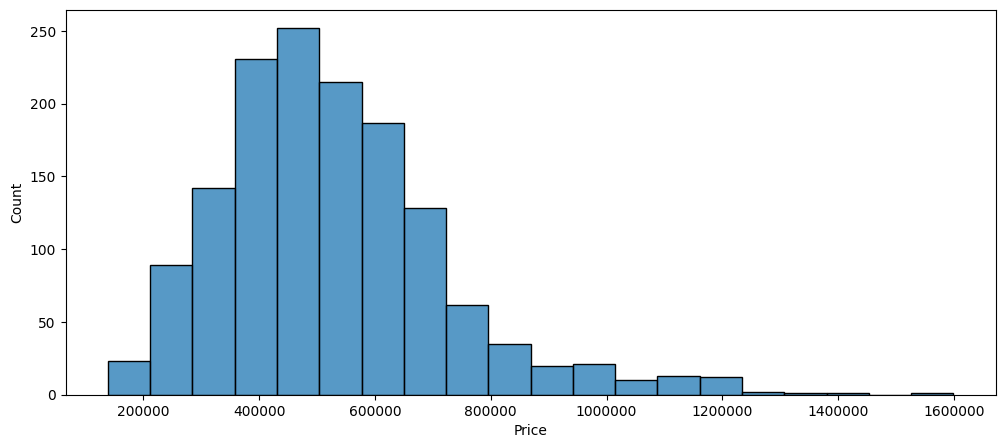

In [3]:
# Visualize the target feature (price)
plt.figure(figsize=(12, 5))
sns.histplot(data=df2, x='Price', bins=20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

The maximum of the used cars are sold at a price range of Rs 3-8 lacs. This is inline with the price from the previous dataset.

In [4]:
# Split the model name between brand, model and varient
df2[['mfg_yr', 'brand', 'model', 'variant']] = df2['Model Name'].str.split(' ', n=3, expand=True)
df2.head(1)

,Model Name,Price,Manufacturing_year,Engine capacity,Spare key,Transmission,KM driven,Ownership,Fuel type,Imperfections,Repainted Parts,mfg_yr,brand,model,variant
0,2017 Maruti Swift VXI,561000,2017,1197,No,Manual,25847,2,Petrol,6,2,2017,Maruti,Swift,VXI


In [5]:
# Check if the manufacturing year in the model name is not correct
df2[df2['Manufacturing_year'].astype(int) != df2['mfg_yr'].astype(int)]

,Model Name,Price,Manufacturing_year,Engine capacity,Spare key,Transmission,KM driven,Ownership,Fuel type,Imperfections,Repainted Parts,mfg_yr,brand,model,variant


In [6]:
# Check the unique variants
df2['variant'].unique()

<ArrowStringArray>
[                   'VXI',       'DELTA PETROL 1.2',            'VXI AT SHVS',
                '800 LXI',                'VXI AMT',              'Dzire VXI',
             'PRESSO VXI',                    'ZXI',       'K10 VXI PLUS AMT',
                  'LXI O',
 ...
             'ZDI + SHVS', 'ZXI PLUS AMT DUAL TONE',               'VXI SHVS',
              'X VXI (O)',                  '5 STR',               'ZDI SHVS',
       'SIGMA DIESEL 1.3',                'ZXI+ RS',        'Brezza ZXI PLUS',
        'S 1.4 MT PETROL']
Length: 180, dtype: str

In [7]:
# Check the unique models
df2['model'].unique()

<ArrowStringArray>
[  'Swift',  'Baleno',  'Ertiga',   'Dzire',    'Alto',       'S', 'Celerio',
   'IGNIS',   'Wagon',    'Ciaz',  'Vitara',  'BREZZA',     'XL6',     'New',
    'Ritz',    'Eeco',   'Grand',    'OMNI',     'Zen',       'A',    'Omni']
Length: 21, dtype: str

In [8]:
# Check for the model name A, NEW and S
df2[df2['model'].isin(['A','S', 'NEW', 'GRAND', 'VITARA'])]['Model Name']

9               2019 Maruti S PRESSO VXI
21             2021 Maruti S PRESSO VXI+
72             2021 Maruti S PRESSO VXI+
144            2021 Maruti S PRESSO VXI+
150     2020 Maruti S PRESSO LXI (O) CNG
                      ...               
1374           2022 Maruti S PRESSO VXI+
1380            2022 Maruti S PRESSO VXI
1384           2022 Maruti S PRESSO VXI+
1389           2021 Maruti S PRESSO VXI+
1409           2020 Maruti S PRESSO VXI+
Name: Model Name, Length: 73, dtype: str

In [9]:
# Replace the model 'A' and 'S' with its full model name
model_mapping = {'A': 'ASTAR', 'S': 'SPRESSO', 'NEW': 'WAGONR', 'WAGON': 'WAGONR', 
                 'GRAND': 'GRANDVITARA', 'VITARA': 'BREZZA'}
df2['model'] = df2['model'].replace(model_mapping)

In [10]:
# Standardize the brand name
df2['brand'] = df2['brand'].replace('Maruti', 'Maruti Suzuki')

In [11]:
# Standardize the variants by fetching again from the model name column
df2['variant'] = df2.apply(lambda row: extract_variant(row['Model Name'], row['brand']), axis=1)
df2.head(1)

,Model Name,Price,Manufacturing_year,Engine capacity,Spare key,Transmission,KM driven,Ownership,Fuel type,Imperfections,Repainted Parts,mfg_yr,brand,model,variant
0,2017 Maruti Swift VXI,561000,2017,1197,No,Manual,25847,2,Petrol,6,2,2017,Maruti Suzuki,Swift,VXI


In [12]:
# Apply the normalization function to the model and variant
df2['model'] = df2['model'].apply(normalize_variant)
df2['variant'] = df2['variant'].apply(normalize_variant)

In [13]:
# Check for unique model and variant after normalization
print('Unique Model\n', df2['model'].unique())
print('Unique Variant\n', df2['variant'].unique())

Unique Model
 <ArrowStringArray>
[  'SWIFT',  'BALENO',  'ERTIGA',   'DZIRE',    'ALTO', 'SPRESSO', 'CELERIO',
   'IGNIS',   'WAGON',    'CIAZ',  'VITARA',  'BREZZA',     'XL6',     'NEW',
    'RITZ',    'EECO',   'GRAND',    'OMNI',     'ZEN',   'ASTAR']
Length: 20, dtype: str
Unique Variant
 <ArrowStringArray>
[    'VXI',   'DELTA',     'LXI',     'ZXI',    'VXI+',   'LXI O',    'ZXI+',
   'ALPHA',  'VXI(O)',    'ZETA',  'ZXI(O)',     'VDI',     'ZDI', 'VXI+(O)',
  'VDI(O)',  'LXI(O)',   'SIGMA',  'ALPHA+',    'ZDI+',  'STD(O)',       nan,
      'LX',       'S',      'RS',   'E STD']
Length: 25, dtype: str


The model and variant name looks good. We can now proceed with exporting the dataset.

### Preparing the Final Dataset

In [14]:
# Create the mapping for dataframe-2
column_mapping = {'Engine capacity': 'engine_capacity_cc', 'Ownership': 'previous_owners', 'mfg_yr': 'make_year', 
                  'KM driven': 'km_driven', 'Fuel type': 'fuel_type', 'Transmission': 'transmission', 
                  'Price': 'price'}

In [15]:
# Rename the columns
df2 = df2.rename(columns=column_mapping)

In [16]:
# Keep only required columns and create missing ones as NaN
df2 = get_final_dataset(df2)
df2.head()

,brand,model,variant,body_type,make_year,state,km_driven,transmission,previous_owners,fuel_type,...,front_brake_type,rear_brake_type,boot_space,fuel_supply_system,alloy_wheel_size,max_power_delivered,max_power_at,max_torque_delivered,max_torque_at,price
0,Maruti Suzuki,SWIFT,VXI,NaN,2017,NaN,25847,Manual,2,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,561000
1,Maruti Suzuki,BALENO,DELTA,NaN,2016,NaN,55511,Manual,2,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,498000
2,Maruti Suzuki,SWIFT,VXI,NaN,2020,NaN,47110,Manual,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,577000
3,Maruti Suzuki,ERTIGA,VXI,NaN,2022,NaN,35378,Automatic,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1084000
4,Maruti Suzuki,DZIRE,VXI,NaN,2019,NaN,91856,Manual,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603000


In [17]:
# Save the standardized dataset into local machine
df2.to_csv(r'.\Cleaned Datasets\dataset_2.csv', index=False)